# 04 — Program size and cost before running anything

**Narrative point 5.** How large is the hardware program, and how does it grow? The memory
experiment is compiled to QIR for H2 (Guppy 0.21 → HUGR → QIR, validation on). The HQC
price comes from a syntax-checker job (aqora or Nexus), pending access; the program
statistics here are what can be measured offline.

**Source:** `python -m qec_timing.hardware.cli scaling` (H2 env) → `results/hardware/qir_scaling.json`.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
sc = json.loads((R / "hardware" / "qir_scaling.json").read_text())
print("versions:", sc["versions"])
print(f"{'d':>3}{'rounds':>8}{'qubits':>8}{'bitcode kB':>12}{'QIR calls':>11}{'RZZ':>7}{'build s':>9}")
for r in sc["rows"]:
    print(f"{r['d']:>3}{r['rounds']:>8}{r['qubits']:>8}{r['bitcode_bytes']/1e3:>12.1f}{r['qir_calls']:>11}{r['rzz']:>7}{r['seconds']:>9.1f}")

versions: {'guppylang': '0.21.11', 'hugr': '0.15.5', 'hugr-qir': '0.1.2', 'pyqir': '0.12.6', 'quantinuum-qircheck': '0.7.0'}
  d  rounds  qubits  bitcode kB  QIR calls    RZZ  build s
  3       2      10         9.0        302     24      2.0
  3       8      10        22.6       1010     96      0.4
  3      32      10        79.8       3842    384      1.5
  5       2      26        21.0        918     80      0.4
  5       8      26        63.7       3138    320      1.2
  5      32      26       264.0      12018   1280      6.5
  7       2      50        39.4       1862    168      0.8
  7       8      50       136.5       6410    672      2.8
  7      16      50       272.8      12474   1344      6.8


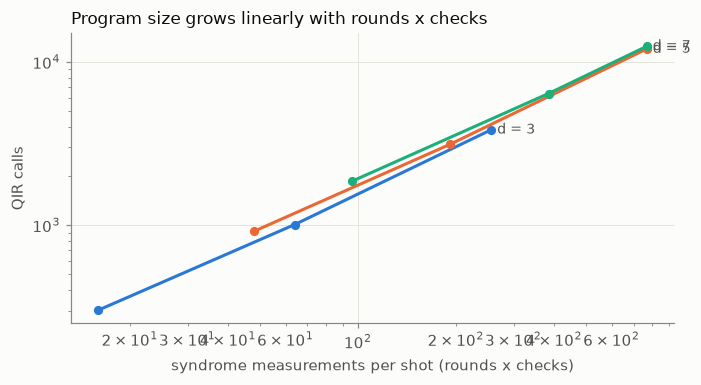

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for d in (3, 5, 7):
    rows = [r for r in sc["rows"] if r["d"] == d]
    x = [r["rounds"] * (d * d - 1) for r in rows]          # check measurements per shot
    y = [r["qir_calls"] for r in rows]
    ax.plot(x, y, "o-", color=P.D_COLOR[d]); P.label_end(ax, x[-1], y[-1], f"d = {d}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("syndrome measurements per shot (rounds x checks)"); ax.set_ylabel("QIR calls")
ax.set_title("Program size grows linearly with rounds x checks", loc="left")
fig.tight_layout()
P.save(fig, "04_program_cost_estimates_1")

**Reading.**
- *Measured:* every program is straight-line (hugr-qir 0.1.2 cannot lower loops), so size
  grows linearly in rounds × checks: one QIR call per gate. d = 7 with 16 rounds is 12,474
  calls and 273 kB, built and validated in about 7 s.
- *Measured:* d = 7 needs 50 qubits, within H2's 56 for the stabilizer emulator; d = 9 (82) does not fit.
- *Interp.:* the RZZ count (one per CNOT) is the dominant cost term in Quantinuum's HQC
  formula, so price scales with rounds × checks too. Extracting less often at fixed total
  time (dt* > 1) cuts it proportionally — the cost side of narrative point 2.
- *Pending access:* the HQC estimate itself (`hardware.cli aqora-check` / `nexus-cost`).